In [1]:
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import snntorch as snn
import snntorch.spikegen as spikegen


df = pd.read_csv("final_data.csv")



In [2]:
df['Flow_delta'] = df['Flow_L_min'].diff()

In [3]:
df['Flow_delta'] = df['Flow_delta'].fillna(0)

In [4]:
df['Flow_low'] = (df['Flow_L_min'] < 0.2).astype(int)

In [5]:
df['Flow_ratio'] = df['Flow_L_min'] / (df['Turbidity_smooth'] + 1)

In [6]:
df.head(50)

,Flow_L_min,label,TDS_smooth,Turbidity_smooth,Flow_delta,Flow_low,Flow_ratio
0,0.27,2,825.6,2532.2,0.00,0,0.000107
1,0.53,1,1229.0,3100.2,0.26,0,0.000171
2,0.27,2,899.0,3121.0,-0.26,0,0.000086
3,0.27,2,816.6,2424.0,0.00,0,0.000111
4,1.33,0,934.2,1662.2,1.06,0,0.000800
5,1.20,0,902.2,1695.4,-0.13,0,0.000707
6,0.27,3,889.0,1713.0,-0.93,0,0.000158
7,1.47,0,1010.8,1677.4,1.20,0,0.000876
8,0.67,3,986.2,2540.0,-0.80,0,0.000264
9,0.13,2,1284.4,2548.0,-0.54,1,0.000051


In [7]:
df['label'].value_counts()

label
1    1095
0     972
2     863
3     615
Name: count, dtype: int64

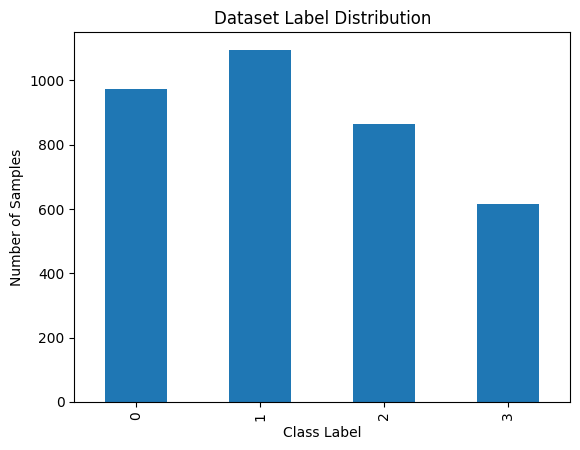

In [8]:
import matplotlib.pyplot as plt

df['label'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Class Label")
plt.ylabel("Number of Samples")
plt.title("Dataset Label Distribution")
plt.show()

In [9]:

X = df[['TDS_smooth','Turbidity_smooth','Flow_L_min','Flow_delta','Flow_low',"Flow_ratio"]]
y = df['label']



X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)


scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train.values)
y_test = torch.tensor(y_test.values)


train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)



num_inputs = 6
num_hidden = 20
num_outputs = 4
num_steps = 40




class Net(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(beta=0.9)

        self.fc2 = nn.Linear(num_hidden, num_outputs)
        self.lif2 = snn.Leaky(beta=0.9)

    def forward(self, x):

        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()

        spk2_rec = []

        for step in range(x.size(0)):

            cur1 = self.fc1(x[step])
            spk1, mem1 = self.lif1(cur1, mem1)

            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)

            spk2_rec.append(spk2)

        return torch.stack(spk2_rec)



model = Net()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)



train_loss_list = []
train_acc_list = []
val_acc_list = []

epochs = 50

for epoch in range(epochs):

    total_loss = 0
    correct = 0
    total = 0

    for data, targets in train_loader:

        spikes = spikegen.rate(data, num_steps=num_steps)

        optimizer.zero_grad()

        spk_out = model(spikes)

        # KEEP ORIGINAL (no change in results)
        loss = loss_fn(spk_out.sum(0), targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        # train accuracy
        _, pred = spk_out.sum(0).max(1)
        correct += (pred == targets).sum().item()
        total += targets.size(0)

    train_loss = total_loss / len(train_loader)
    train_acc = correct / total

    # validation accuracy
    with torch.no_grad():
        test_spikes = spikegen.rate(X_test, num_steps=num_steps)
        test_spk = model(test_spikes)
        _, test_pred = test_spk.sum(0).max(1)
        val_acc = (test_pred == y_test).float().mean().item()

    train_loss_list.append(train_loss)
    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)

    print(f"Epoch {epoch} | Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

Epoch 0 | Loss: 1.2785 | Train Acc: 0.4725 | Val Acc: 0.7574
Epoch 1 | Loss: 0.6241 | Train Acc: 0.7489 | Val Acc: 0.7659
Epoch 2 | Loss: 0.5117 | Train Acc: 0.8022 | Val Acc: 0.7842
Epoch 3 | Loss: 0.5039 | Train Acc: 0.7941 | Val Acc: 0.8025
Epoch 4 | Loss: 0.4458 | Train Acc: 0.8117 | Val Acc: 0.8307
Epoch 5 | Loss: 0.4099 | Train Acc: 0.8181 | Val Acc: 0.8237
Epoch 6 | Loss: 0.3910 | Train Acc: 0.8286 | Val Acc: 0.8505
Epoch 7 | Loss: 0.3803 | Train Acc: 0.8364 | Val Acc: 0.8223
Epoch 8 | Loss: 0.3969 | Train Acc: 0.8272 | Val Acc: 0.8223
Epoch 9 | Loss: 0.3746 | Train Acc: 0.8364 | Val Acc: 0.8406
Epoch 10 | Loss: 0.3832 | Train Acc: 0.8325 | Val Acc: 0.8209
Epoch 11 | Loss: 0.3834 | Train Acc: 0.8364 | Val Acc: 0.8096
Epoch 12 | Loss: 0.3909 | Train Acc: 0.8262 | Val Acc: 0.8364
Epoch 13 | Loss: 0.3830 | Train Acc: 0.8353 | Val Acc: 0.8209
Epoch 14 | Loss: 0.3935 | Train Acc: 0.8258 | Val Acc: 0.8336
Epoch 15 | Loss: 0.3585 | Train Acc: 0.8357 | Val Acc: 0.8181
Epoch 16 | Loss: 0

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# convert tensors to CPU numpy
y_true = y_test.cpu().numpy()
y_pred = test_pred.cpu().numpy()

# overall metrics
acc = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Accuracy  : 0.8660
Precision : 0.8640
Recall    : 0.8660
F1 Score  : 0.8643


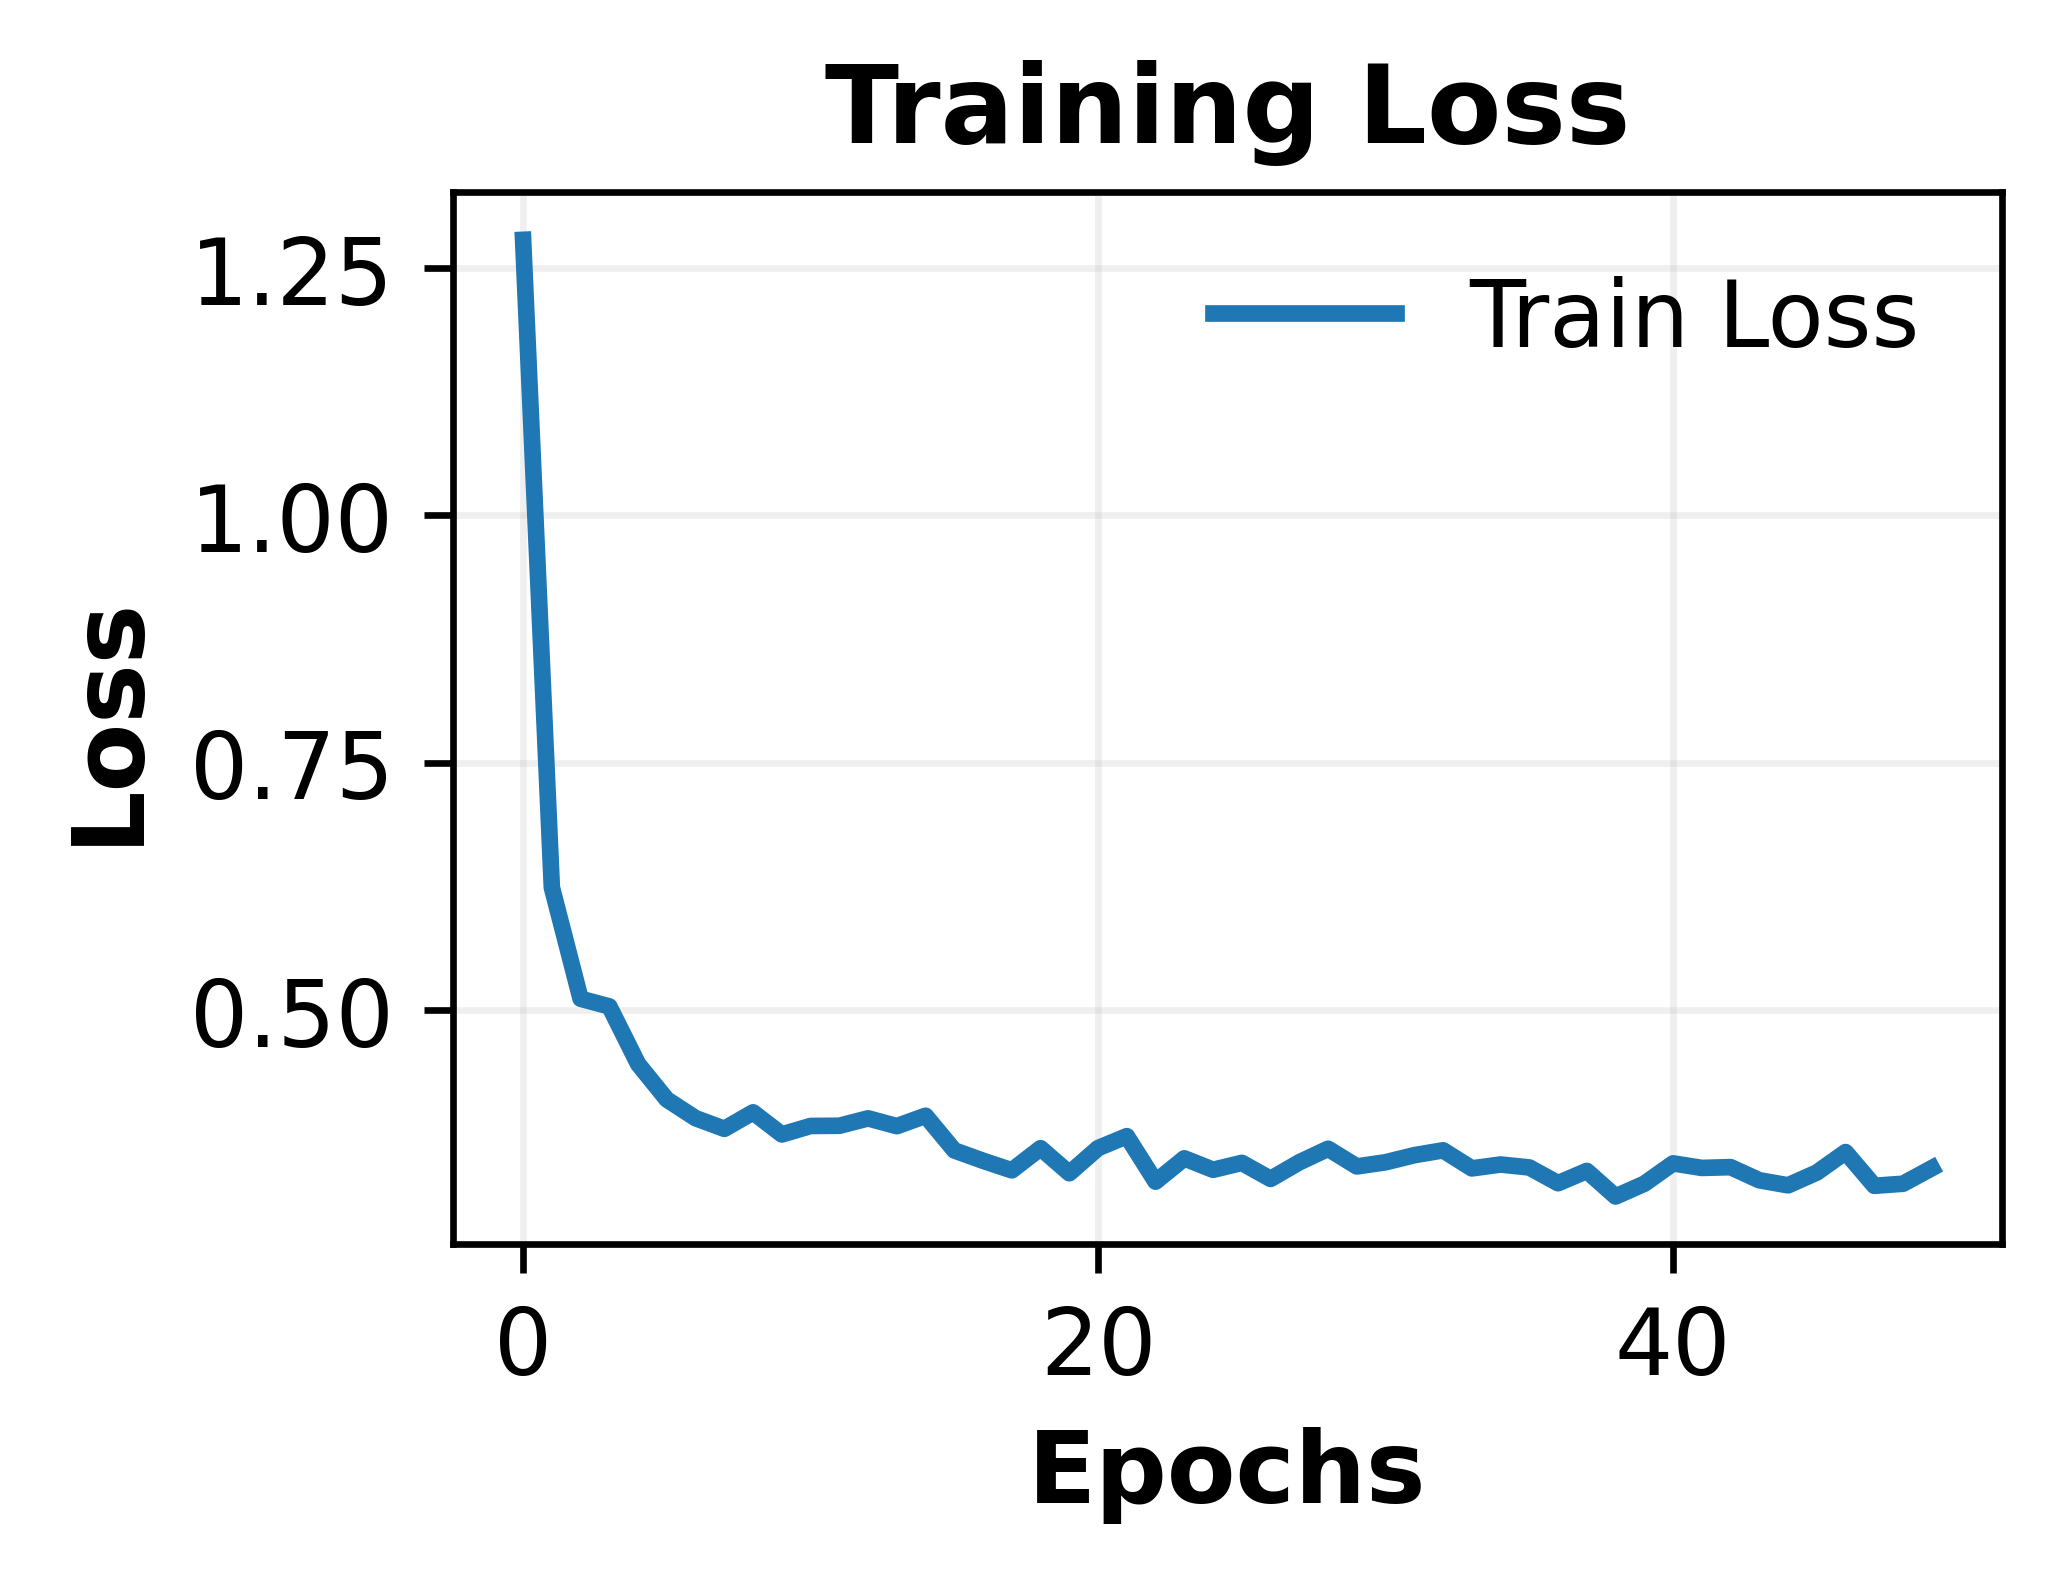

In [24]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 12,              # overall smaller
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.titleweight": "bold",   # bold title
    "axes.labelweight": "bold",   # bold labels
    "lines.linewidth": 2,
})

# Compact size for paper column
plt.figure(figsize=(3.5, 2.8), dpi=600)

plt.plot(train_loss_list, label="Train Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.legend(frameon=False)
plt.grid(alpha=0.2)

plt.tight_layout()

# Save for paper
plt.savefig("training_loss.pdf", bbox_inches='tight')
plt.savefig("training_loss.png", dpi=600, bbox_inches='tight')

plt.show()

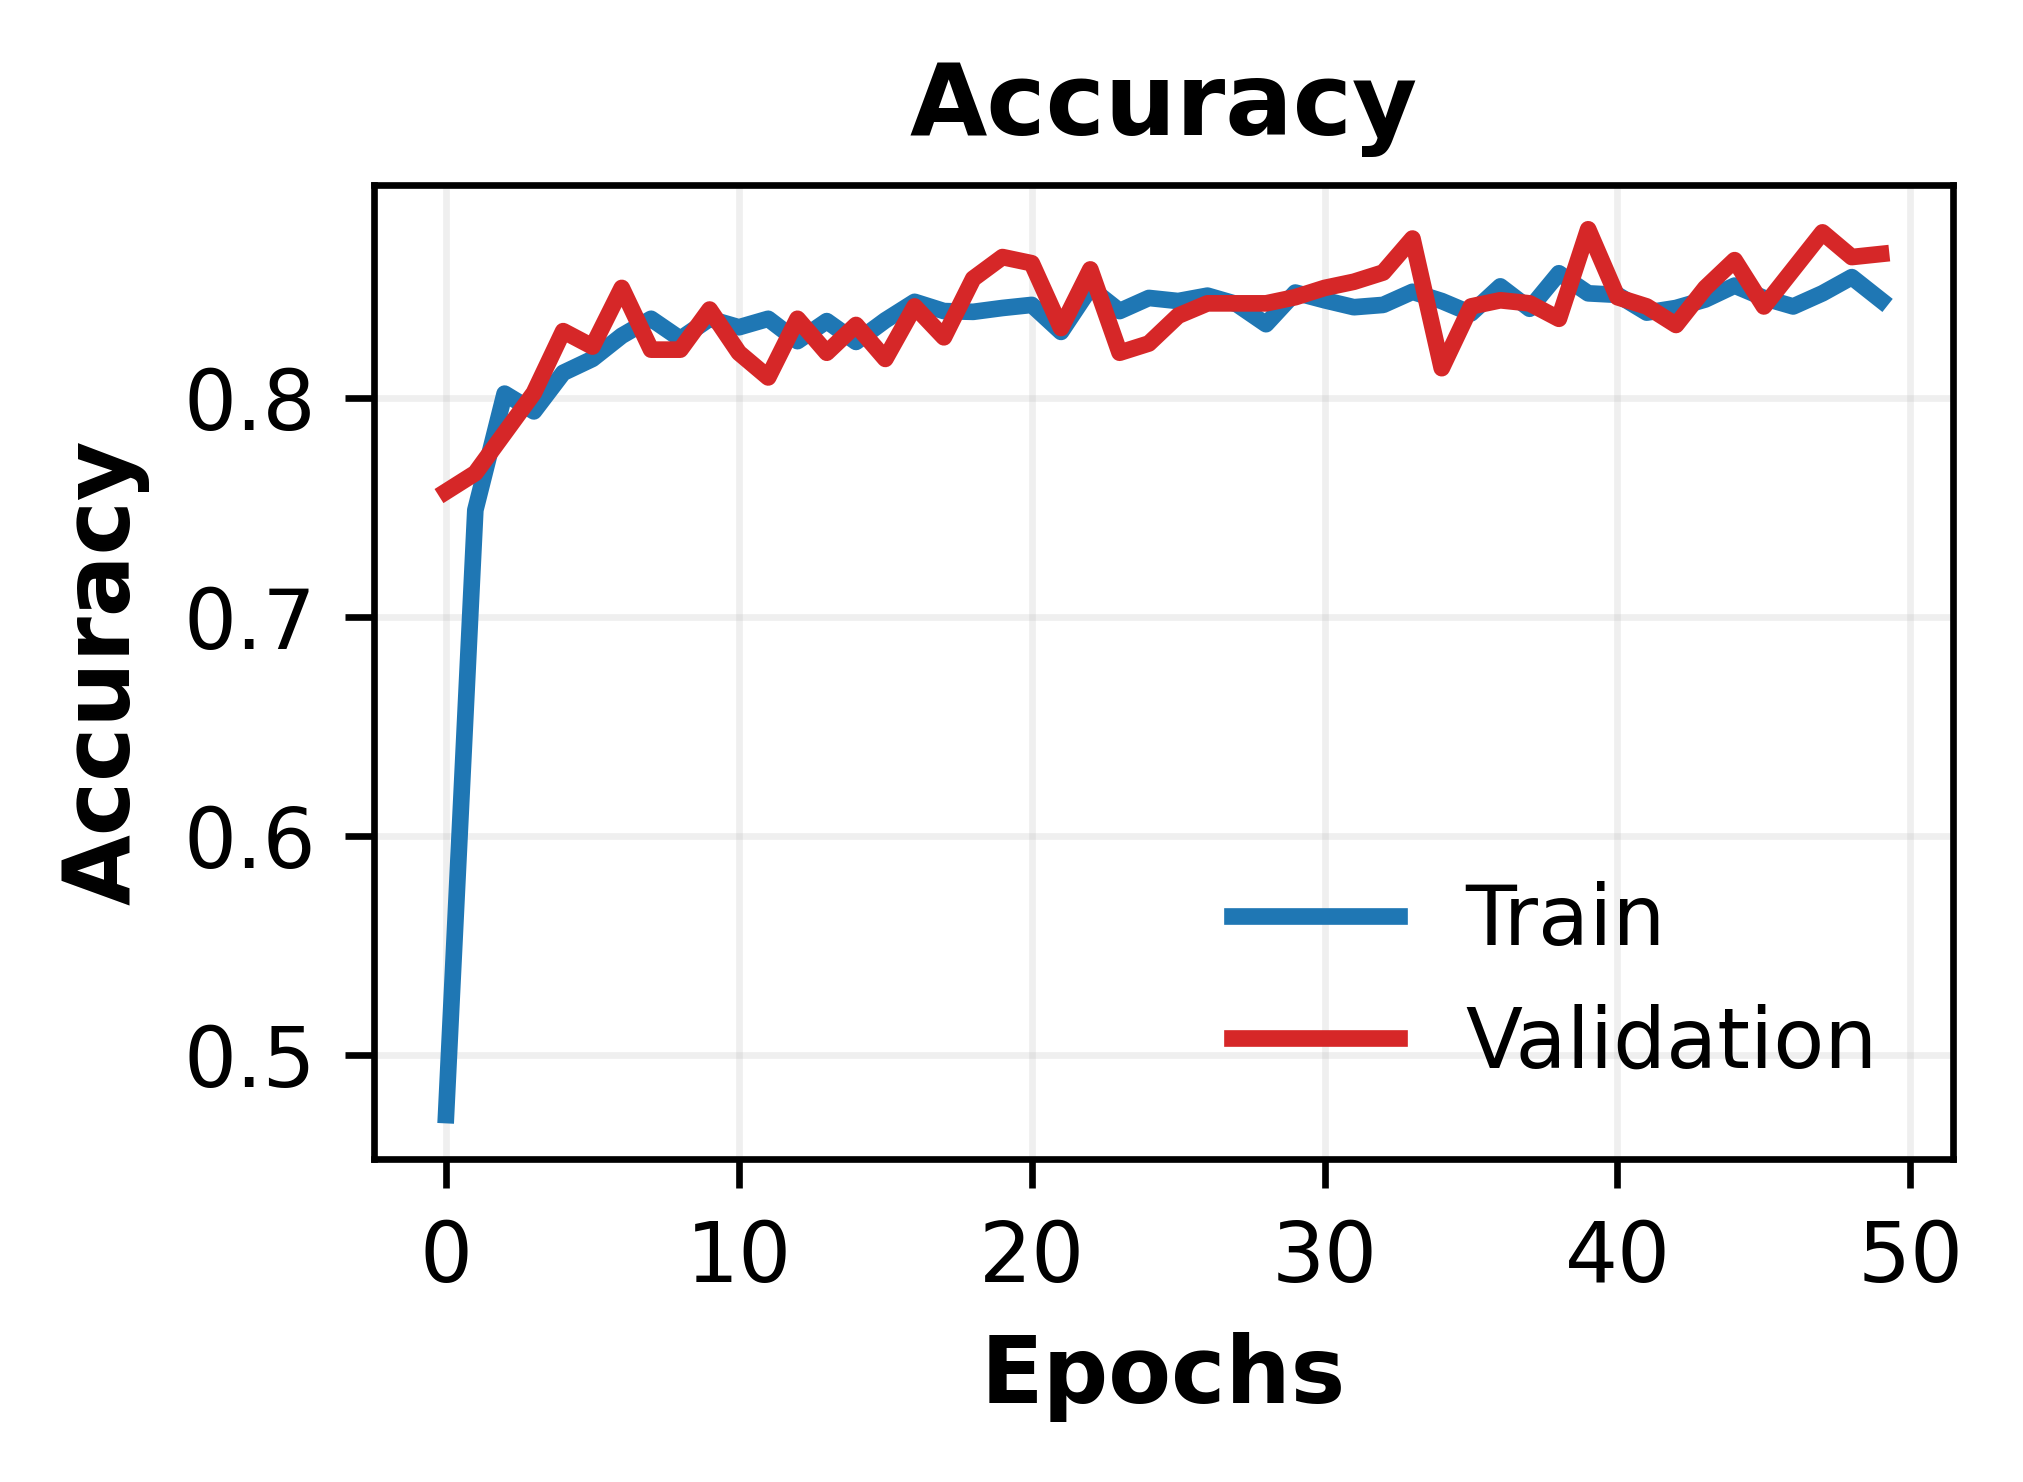

In [31]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "lines.linewidth": 2,
})

plt.figure(figsize=(3.5, 2.6), dpi=600)

# Solid lines for both
plt.plot(train_acc_list, label="Train", color="#1f77b4")
plt.plot(val_acc_list, label="Validation", color="#d62728")  # changed color + no dashed

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy")

plt.legend(loc="lower right", frameon=False)
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig("accuracy_fixed.pdf", bbox_inches='tight')
plt.savefig("accuracy_fixed.png", dpi=600, bbox_inches='tight')

plt.show()

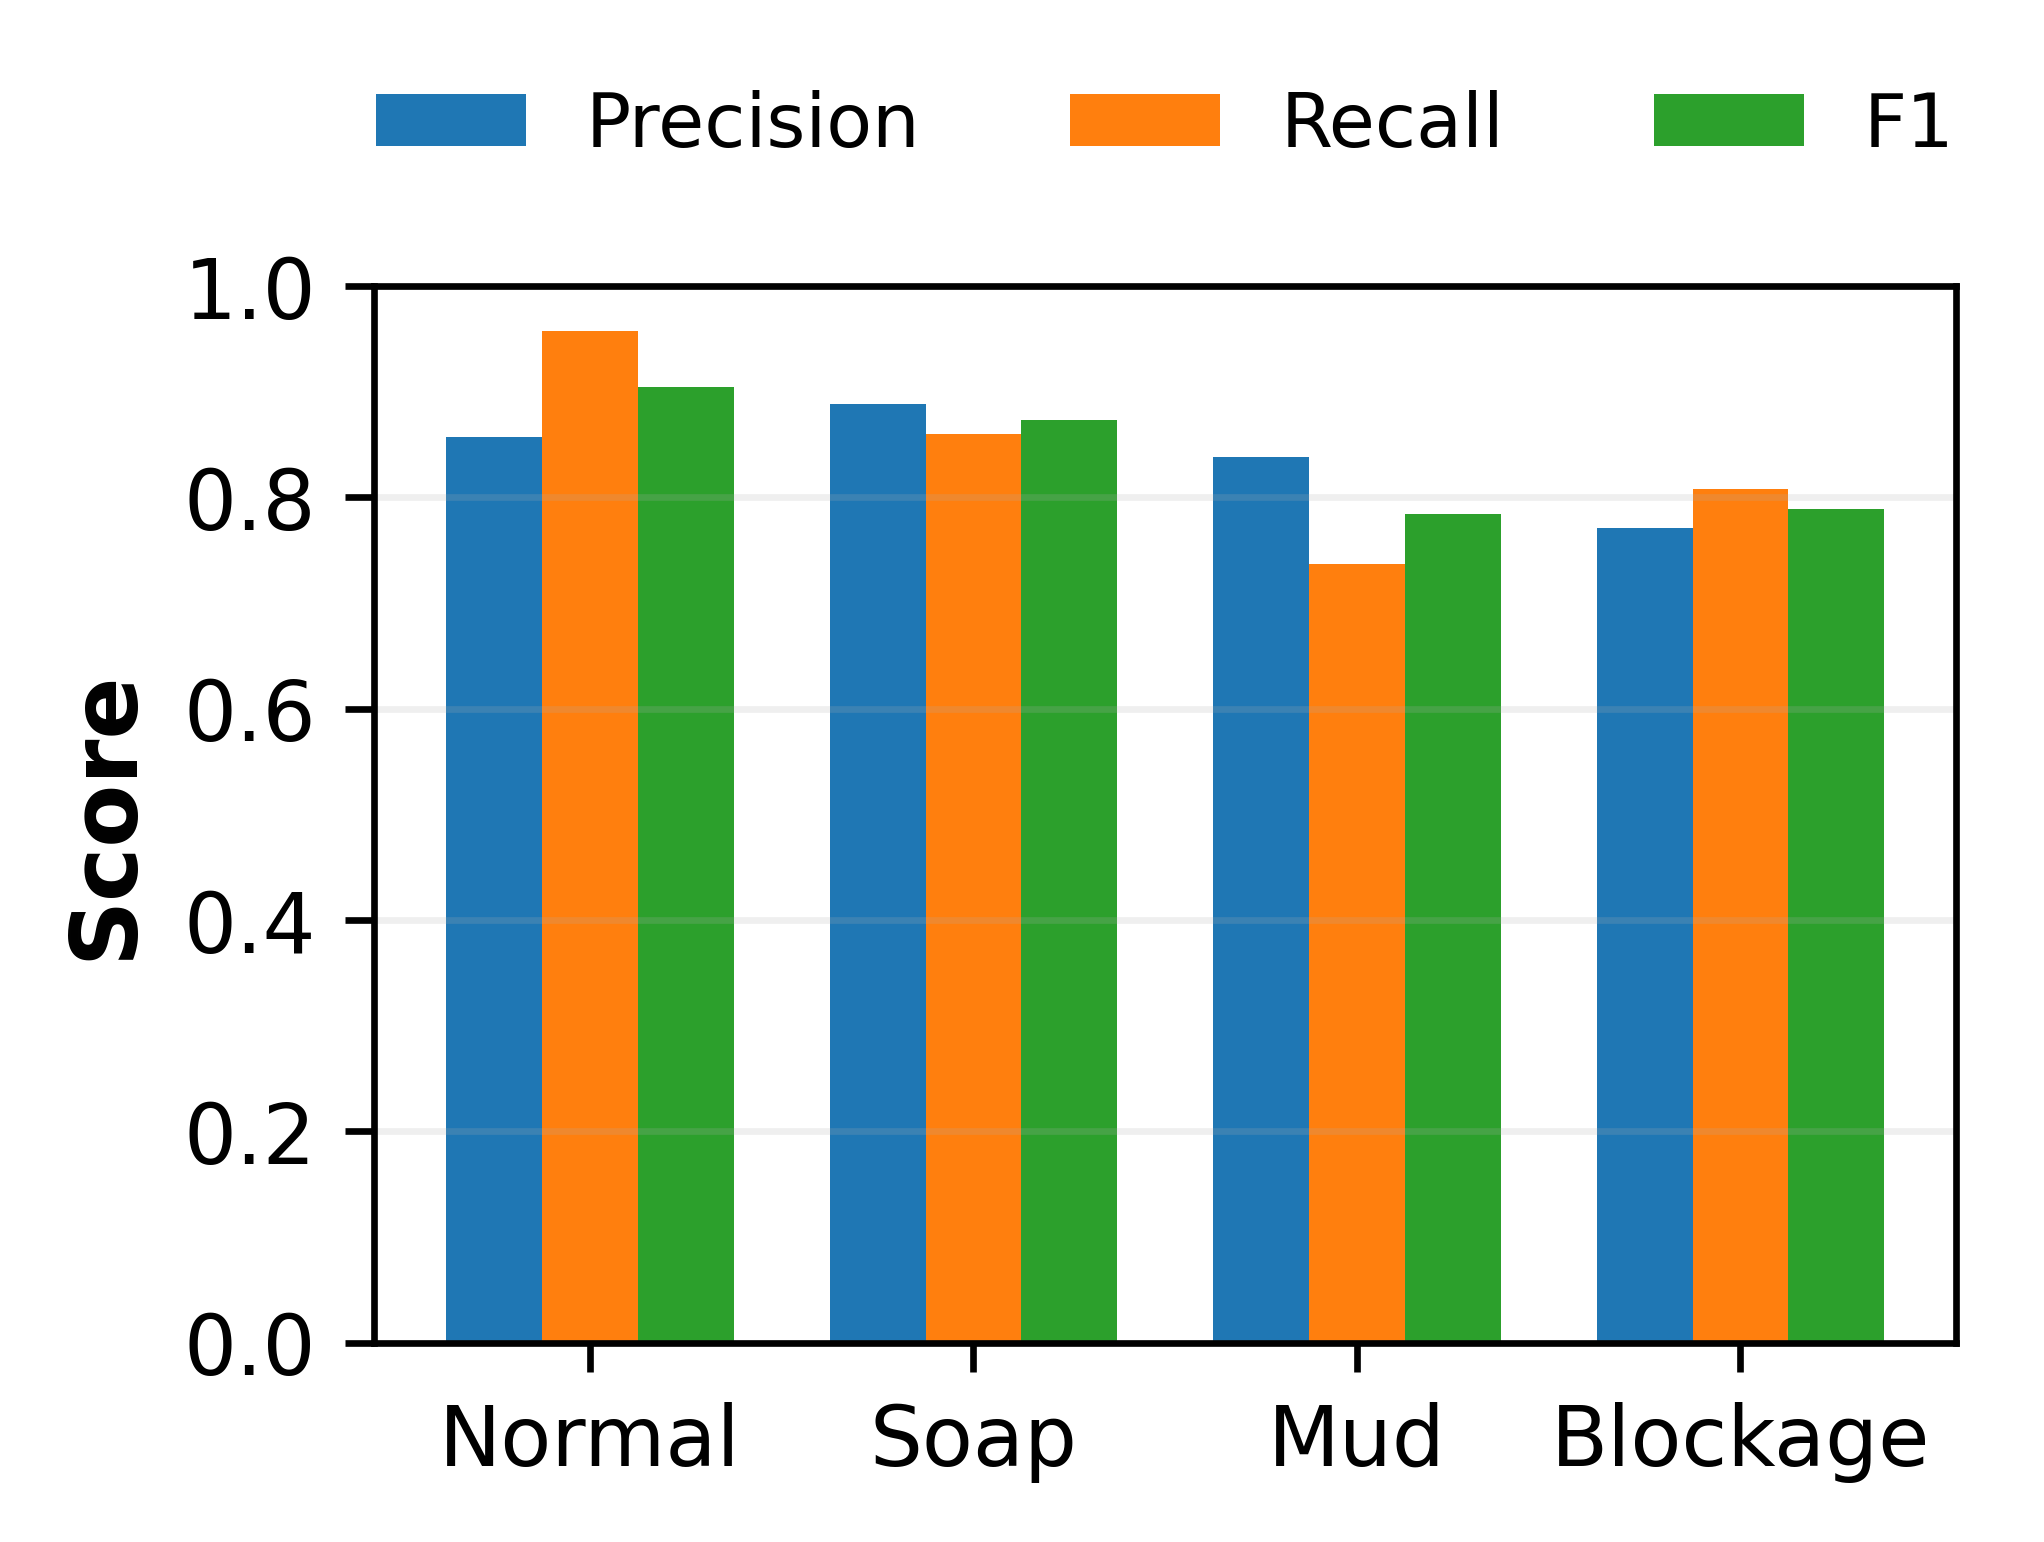

In [33]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Normal", "Soap", "Mud", "Blockage"]
x = np.arange(len(labels))

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
})

plt.figure(figsize=(3.5, 2.8), dpi=600)

width = 0.25

# Bars
plt.bar(x - width, precision, width=width, label="Precision", color="#1f77b4")
plt.bar(x, recall, width=width, label="Recall", color="#ff7f0e")
plt.bar(x + width, f1, width=width, label="F1", color="#2ca02c")

plt.xticks(x, labels)
plt.ylabel("Score")

# ❗ Remove title (better for papers)
# plt.title("Class-wise Performance")

plt.ylim(0, 1)

# Move legend OUTSIDE (very important fix)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.25), ncol=3, frameon=False)

plt.grid(axis='y', alpha=0.2)

plt.tight_layout()

plt.savefig("class_performance_fixed.pdf", bbox_inches='tight')
plt.savefig("class_performance_fixed.png", dpi=600, bbox_inches='tight')

plt.show()

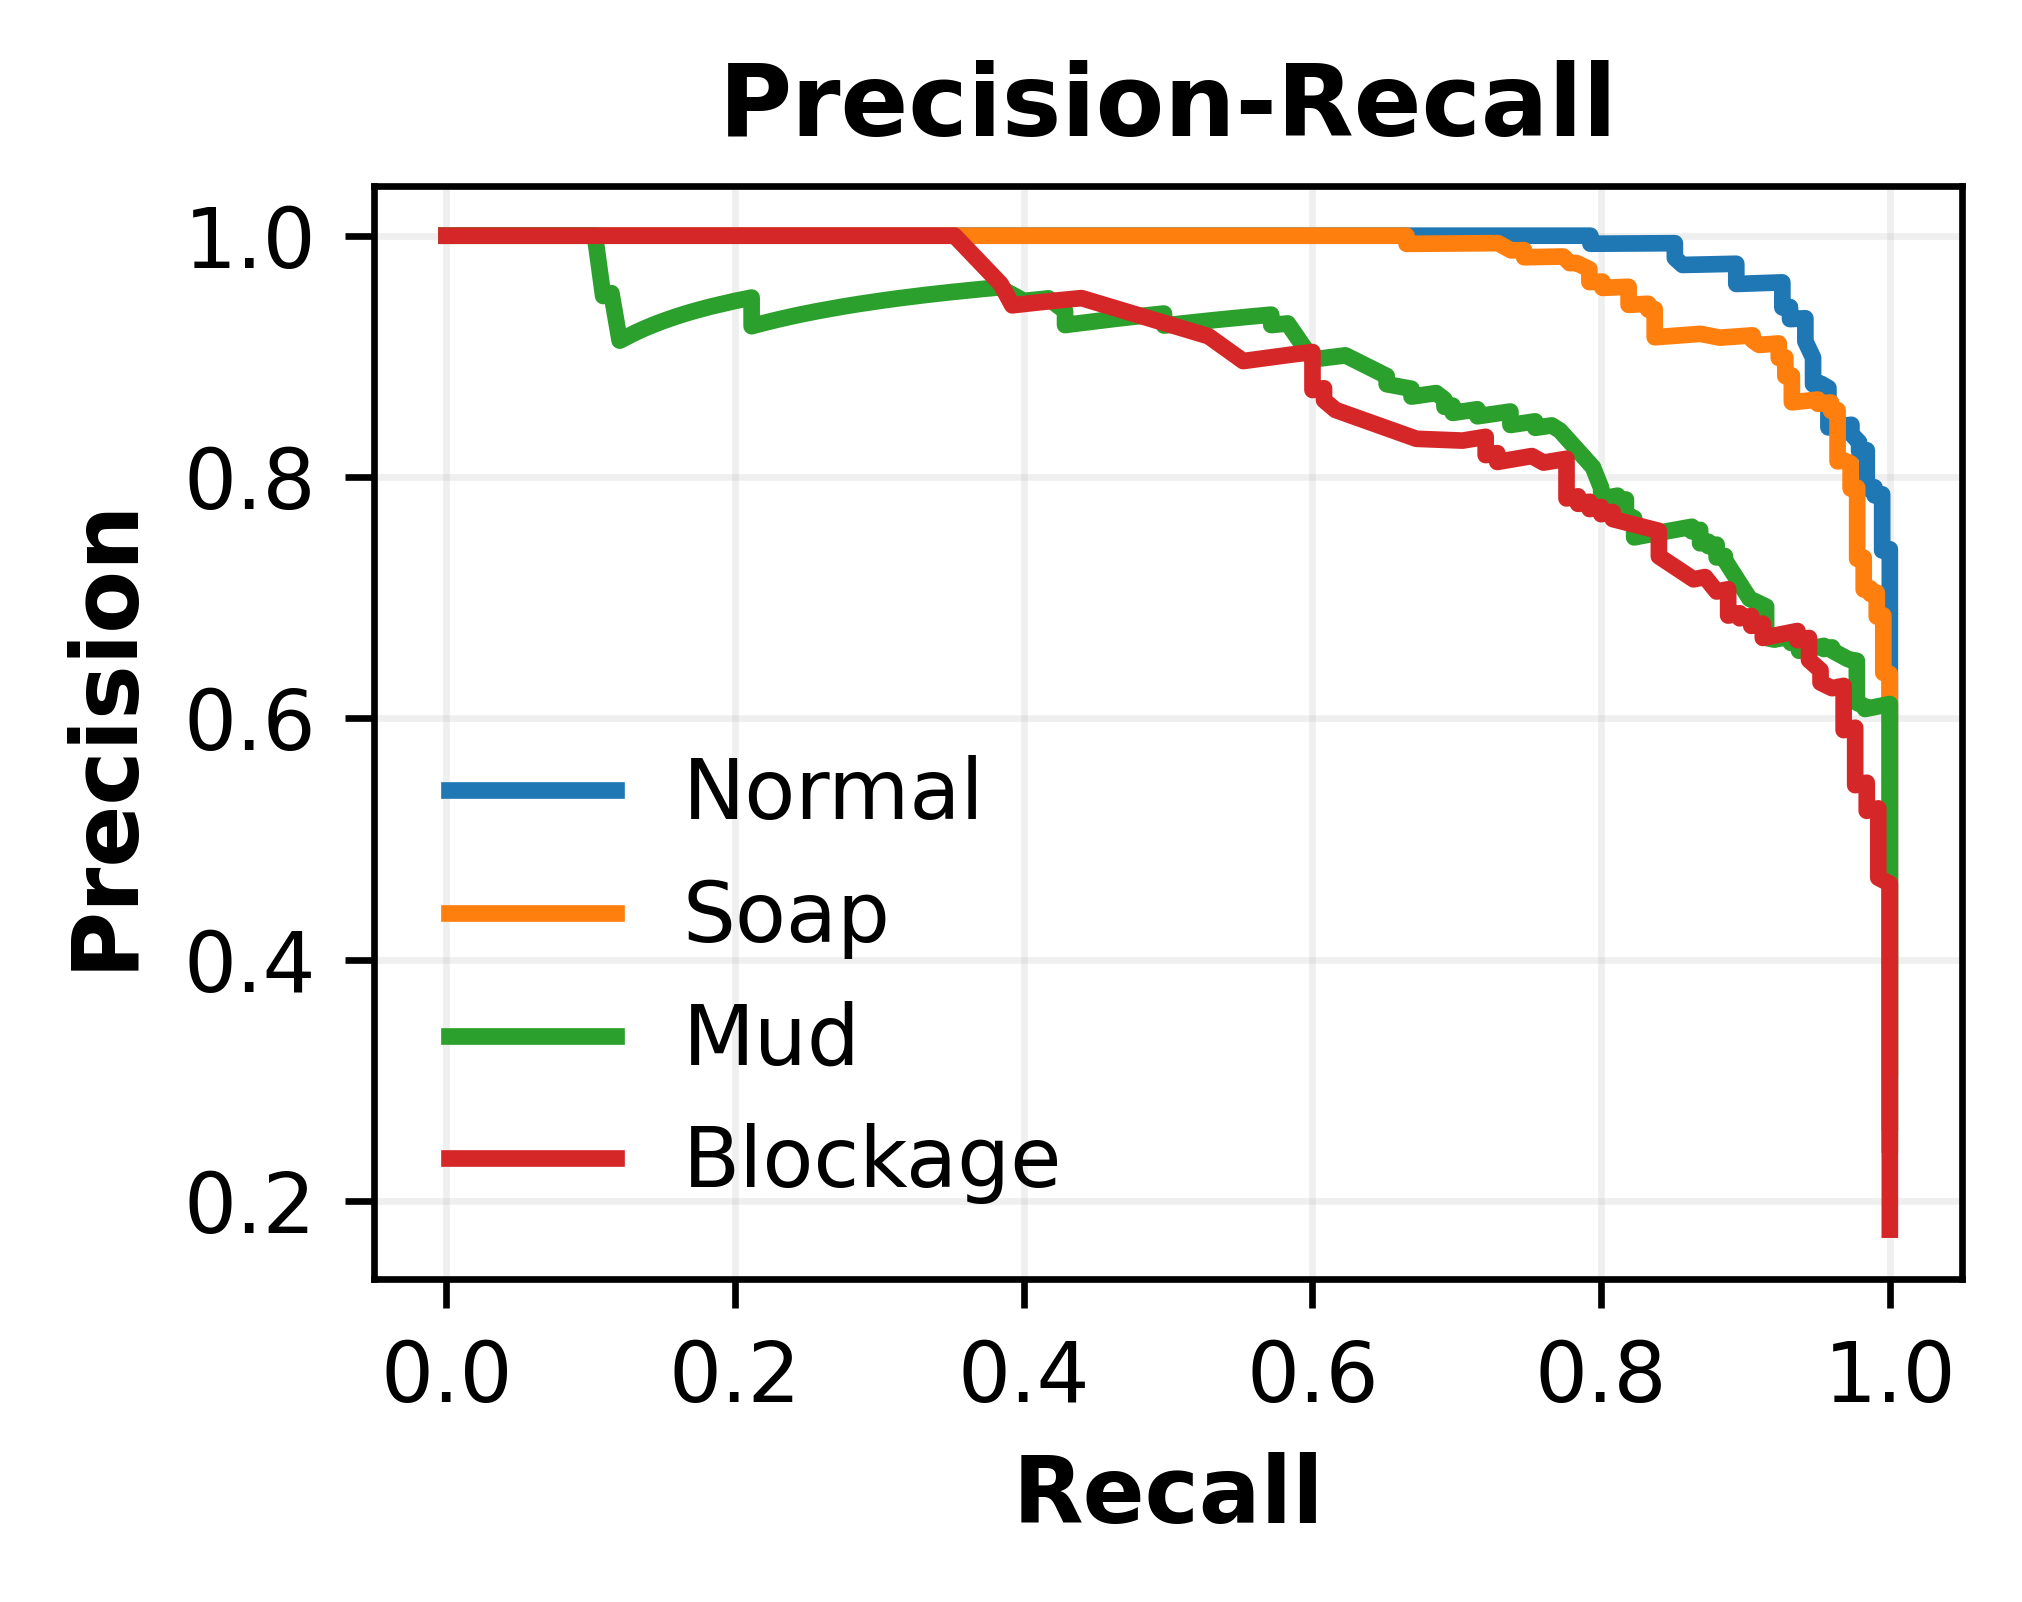

In [35]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "lines.linewidth": 2,
})

plt.figure(figsize=(3.5, 2.8), dpi=600)

for i in range(4):
    p, r, _ = precision_recall_curve(y_bin[:, i], scores[:, i])
    plt.plot(r, p, label=labels[i])

plt.xlabel("Recall")
plt.ylabel("Precision")

# Make title smaller or remove (better for papers)
plt.title("Precision-Recall")

plt.legend(frameon=False, loc="lower left")
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig("pr_curve_fixed.pdf", bbox_inches='tight')
plt.savefig("pr_curve_fixed.png", dpi=600, bbox_inches='tight')

plt.show()

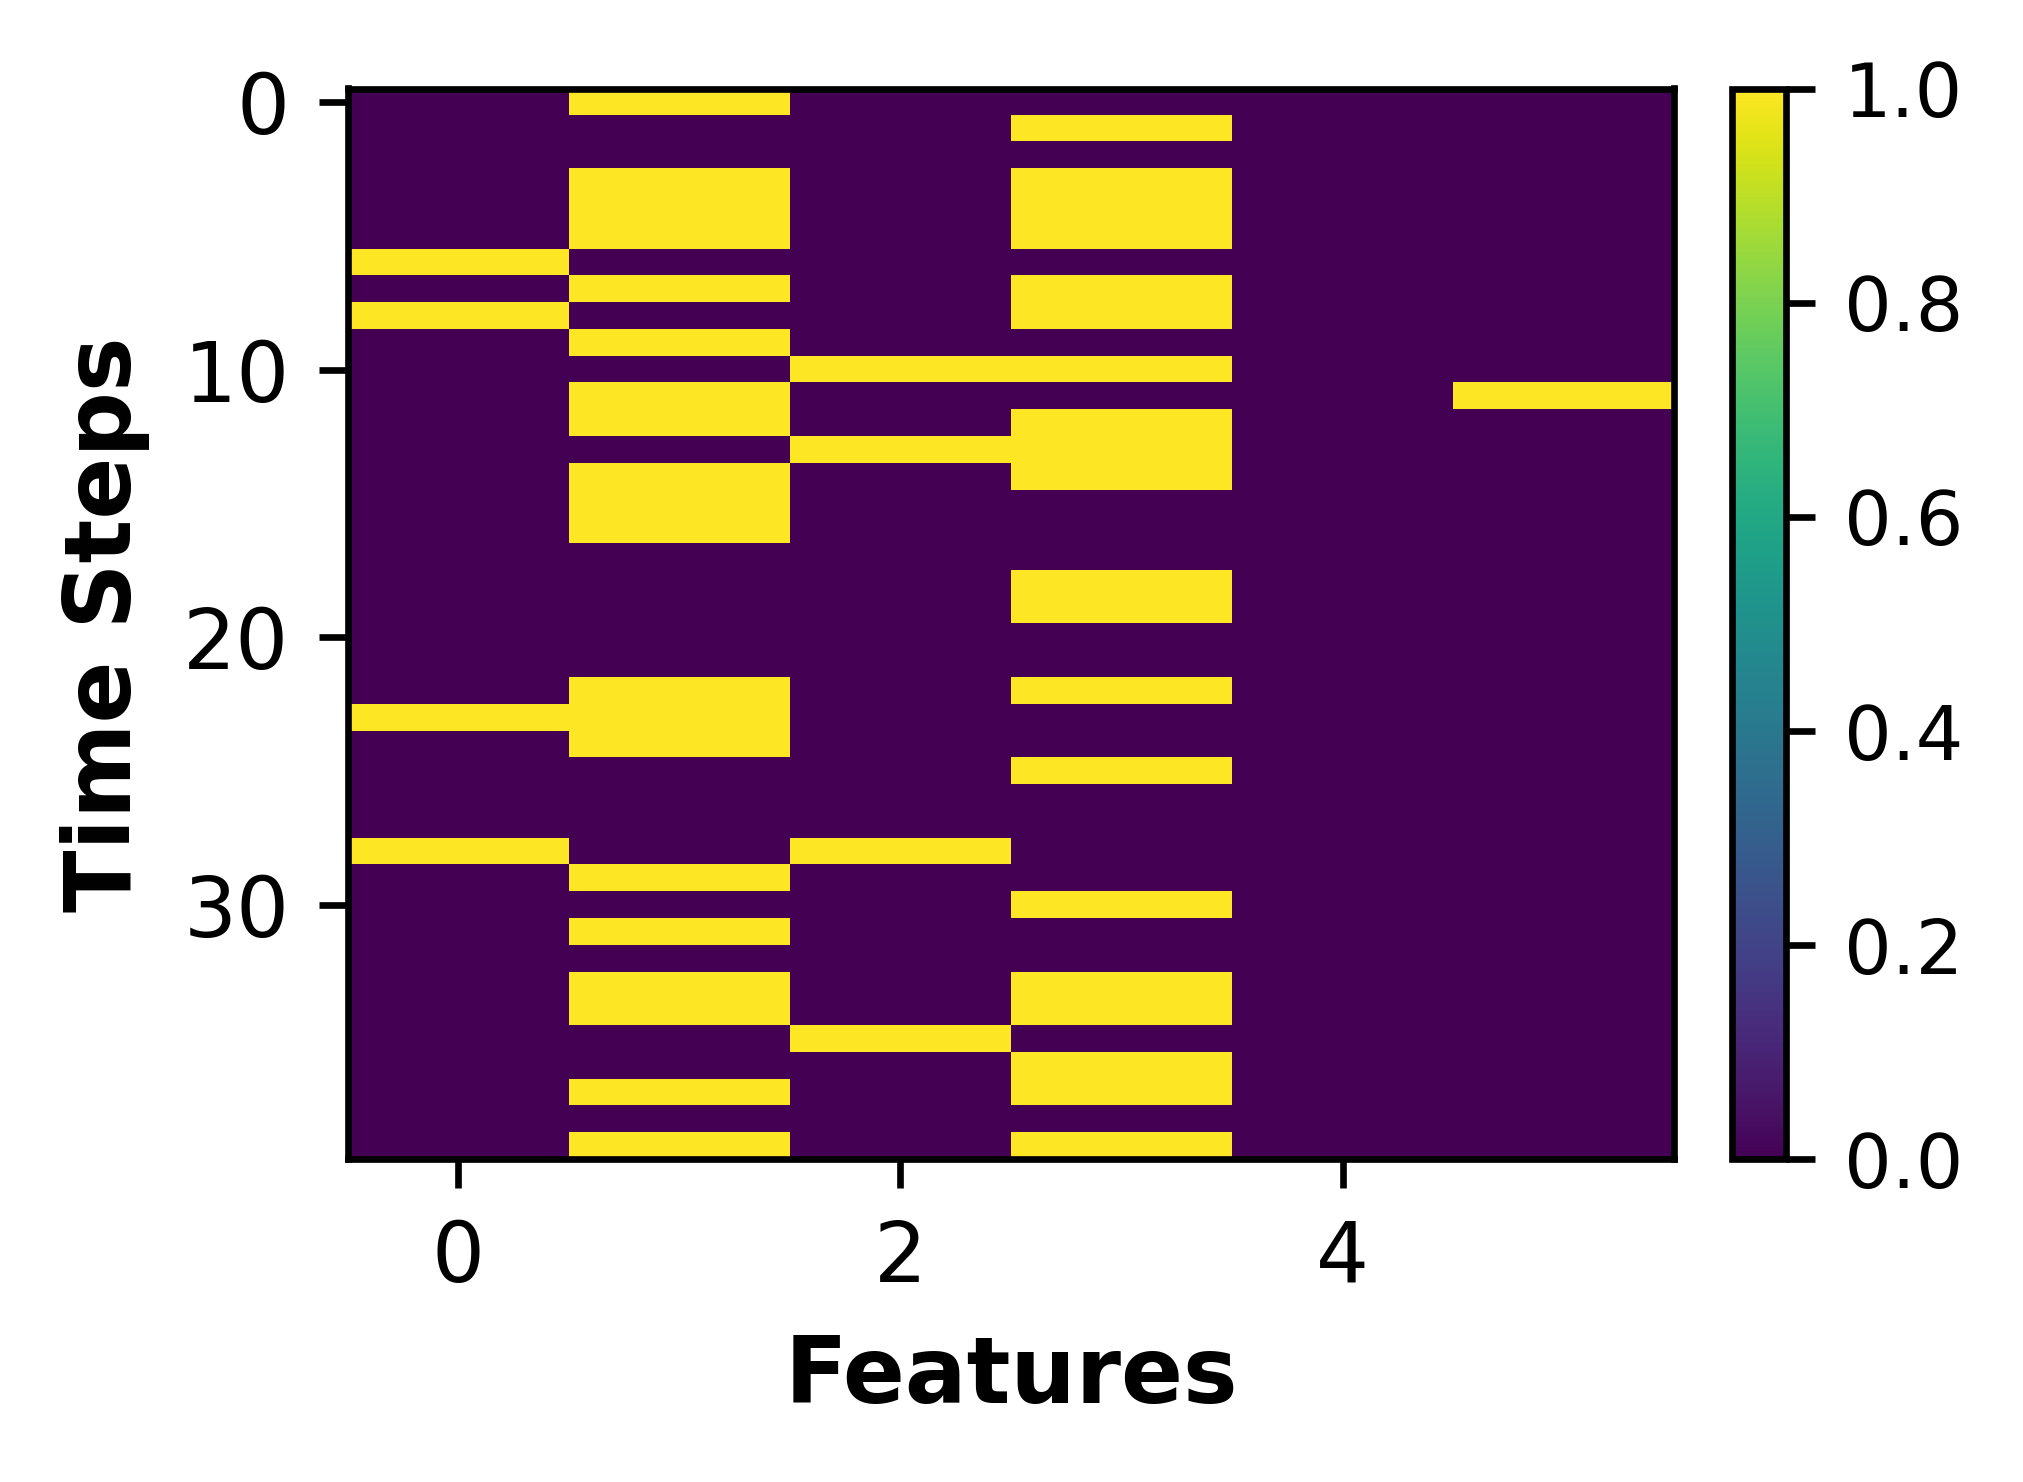

In [36]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
})

plt.figure(figsize=(3.5, 2.6), dpi=600)

sample_spikes = test_spikes[:, 0, :].cpu()

im = plt.imshow(sample_spikes, aspect='auto', cmap='viridis')

plt.xlabel("Features")
plt.ylabel("Time Steps")

# Optional: remove title for paper
# plt.title("Spike Activity")

# Smaller, clean colorbar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()

plt.savefig("spike_activity.pdf", bbox_inches='tight')
plt.savefig("spike_activity.png", dpi=600, bbox_inches='tight')

plt.show()

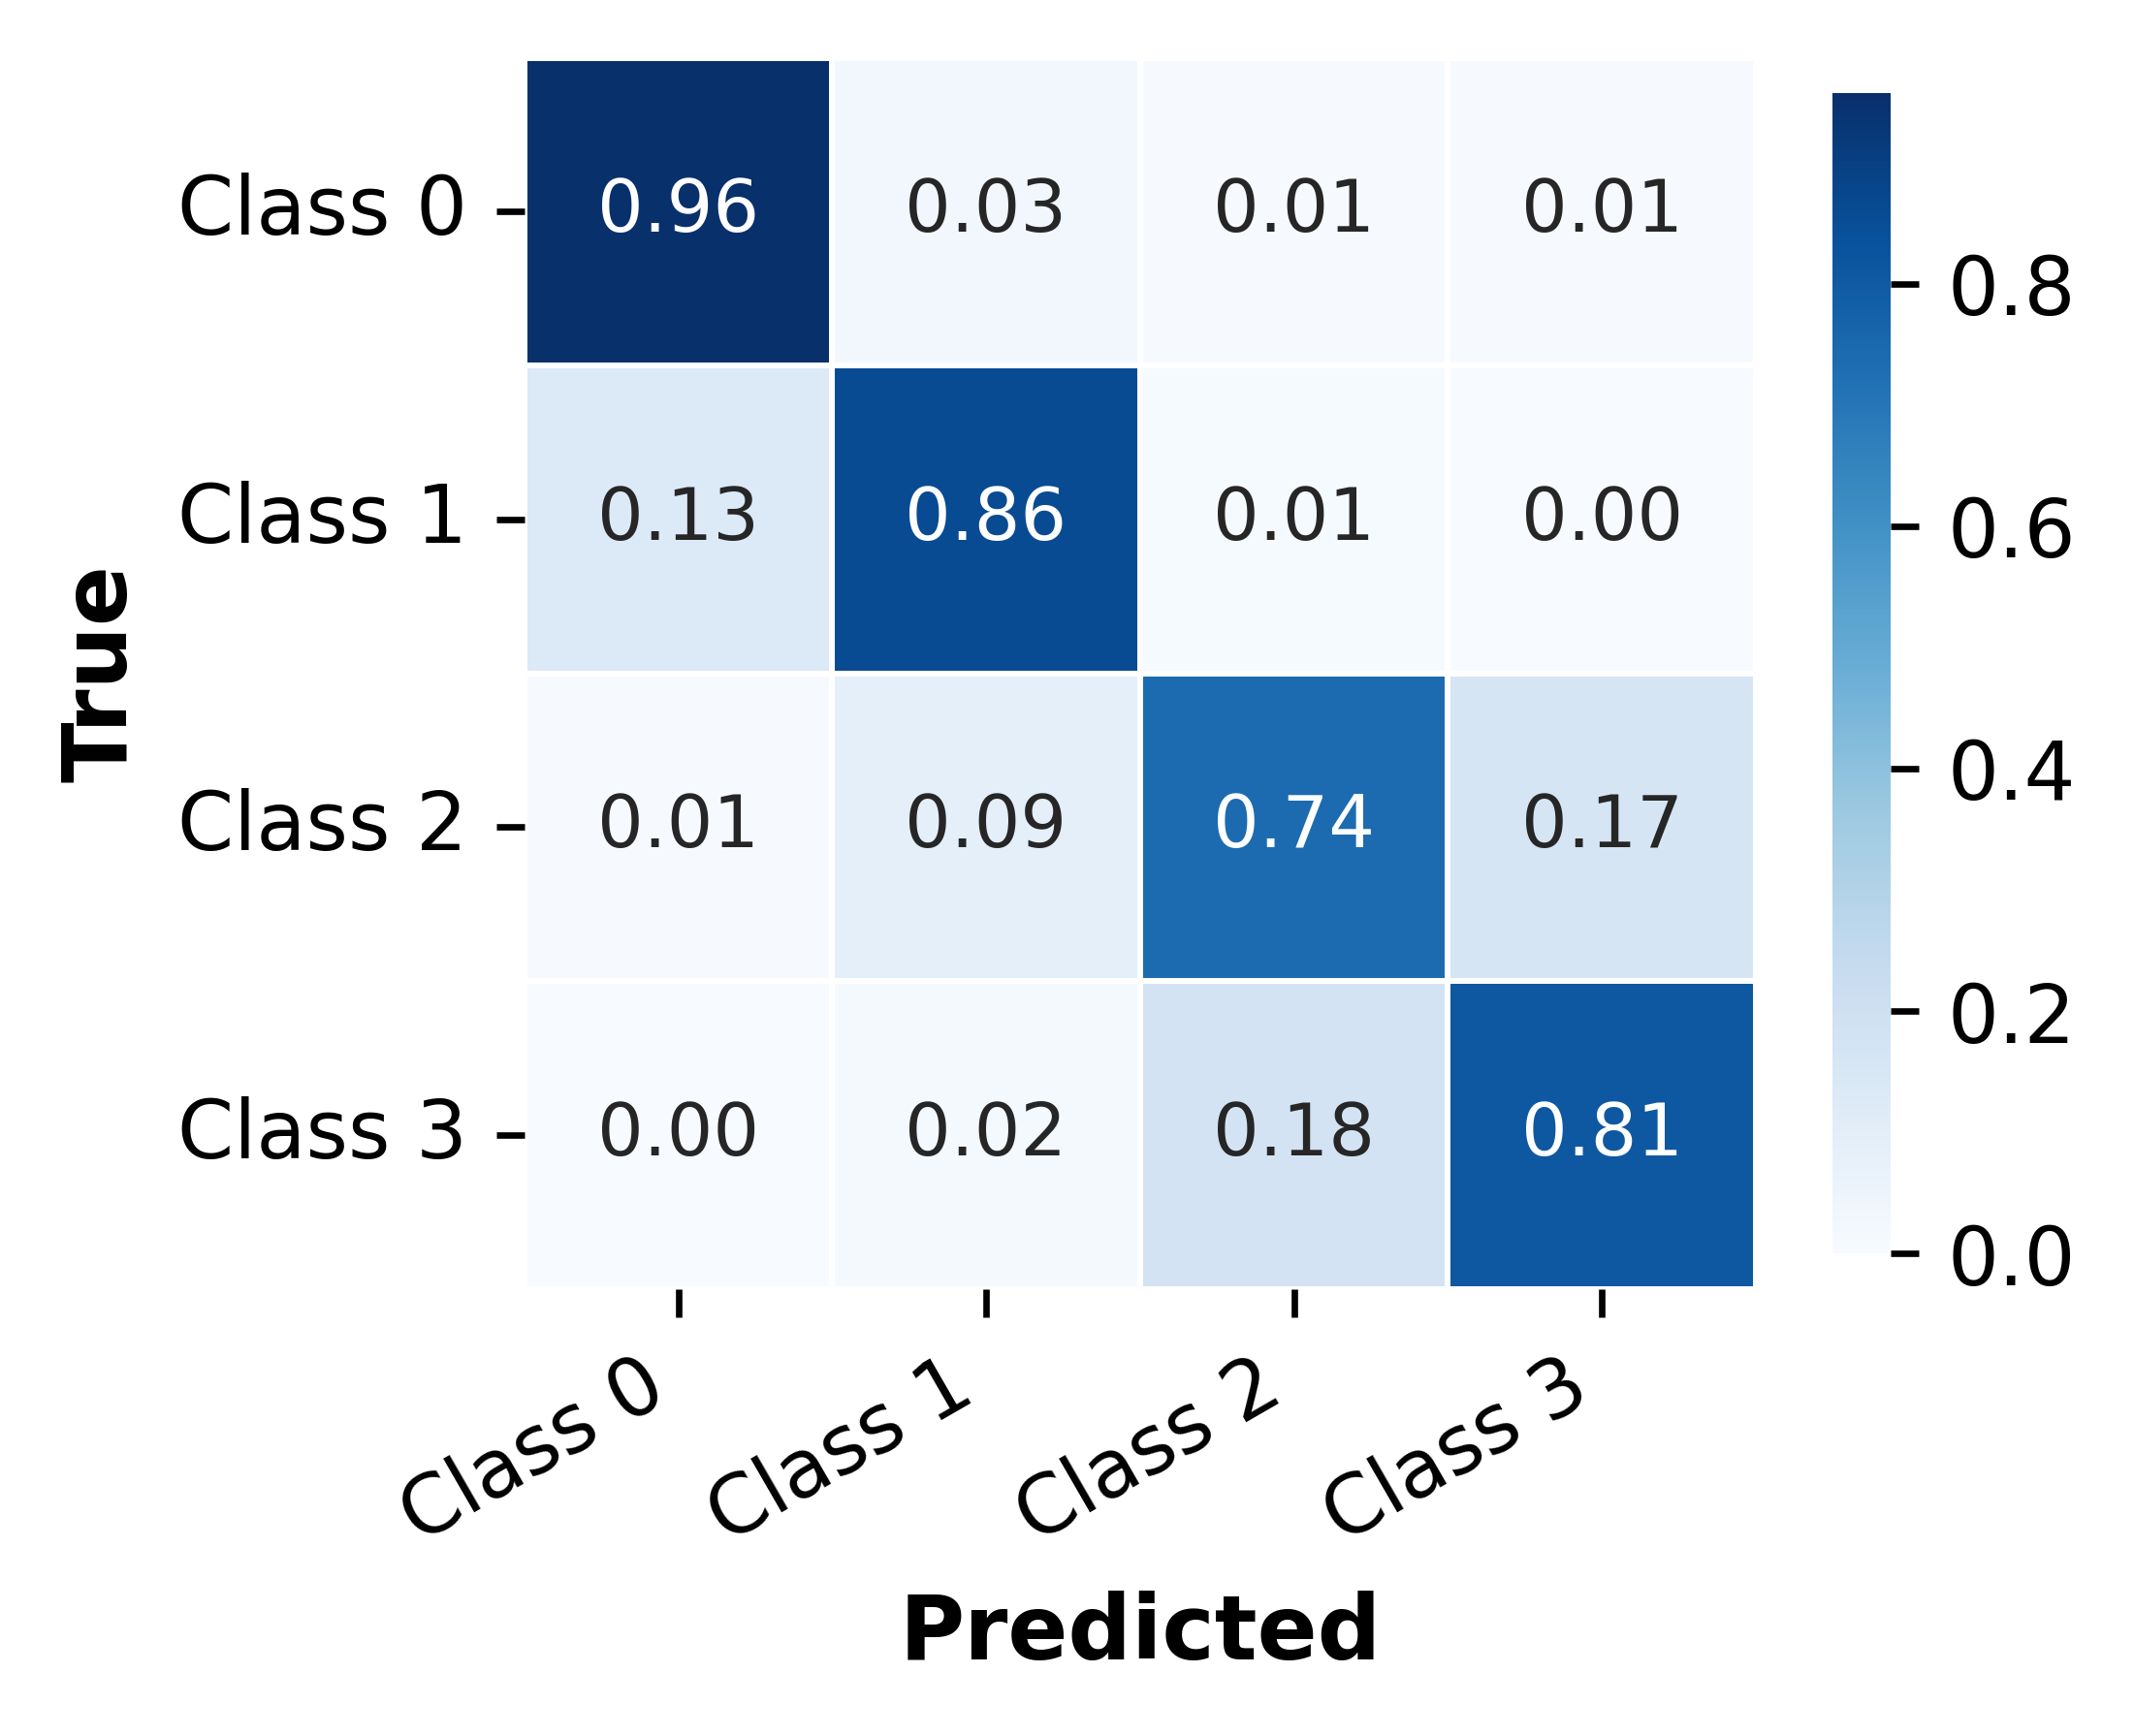

In [39]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predicted)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

labels = ["Class 0", "Class 1", "Class 2", "Class 3"]

plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.labelweight": "bold",
})

plt.figure(figsize=(3.6, 3.2), dpi=600)

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 9}
)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout(pad=0.5)

plt.savefig("confusion_matrix_class.pdf", bbox_inches='tight')
plt.savefig("confusion_matrix_class.png", dpi=600, bbox_inches='tight')

plt.show()

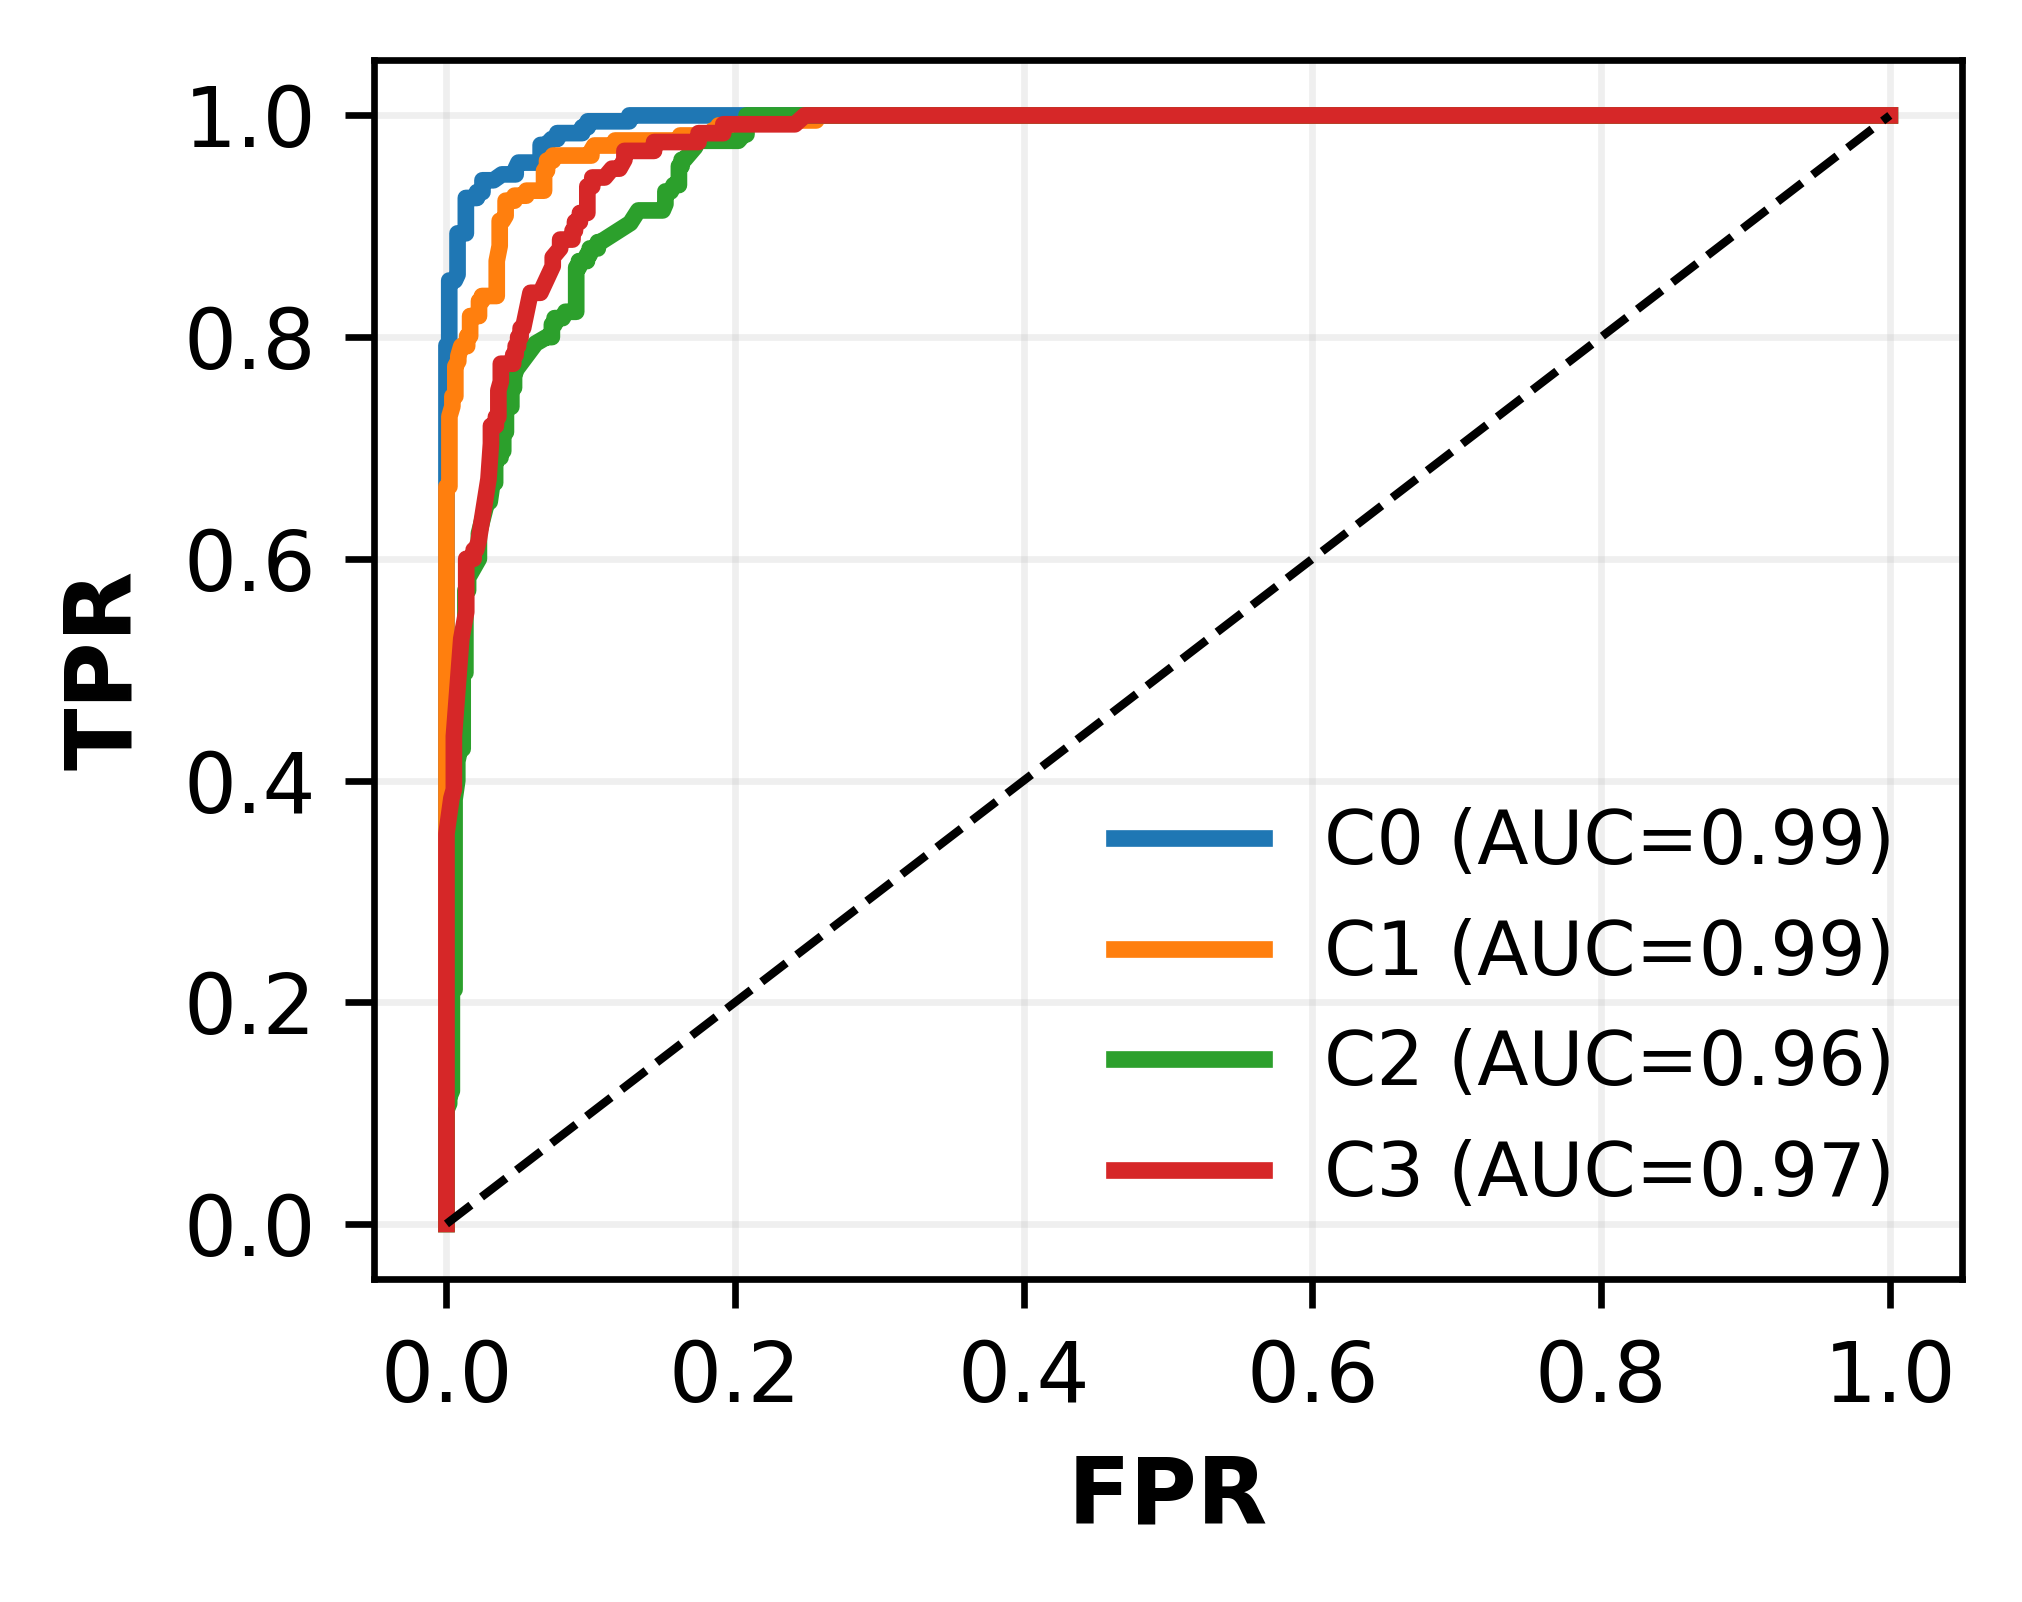

In [40]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Binarize labels
y_bin = label_binarize(y_test, classes=[0,1,2,3])

# Convert spike output to probabilities
scores = torch.softmax(test_spk.sum(0), dim=1).detach().cpu().numpy()

n_classes = y_bin.shape[1]

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "lines.linewidth": 2,
})

# Compact column-sized figure
plt.figure(figsize=(3.5, 2.8), dpi=600)

# Plot ROC curves
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], scores[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"C{i} (AUC={roc_auc:.2f})")

# Diagonal reference
plt.plot([0,1], [0,1], 'k--', linewidth=1)

plt.xlabel("FPR")
plt.ylabel("TPR")

# Optional: remove title for paper
# plt.title("ROC Curve")

plt.legend(loc="lower right", frameon=False)
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig("roc_curve.pdf", bbox_inches='tight')
plt.savefig("roc_curve.png", dpi=600, bbox_inches='tight')

plt.show()

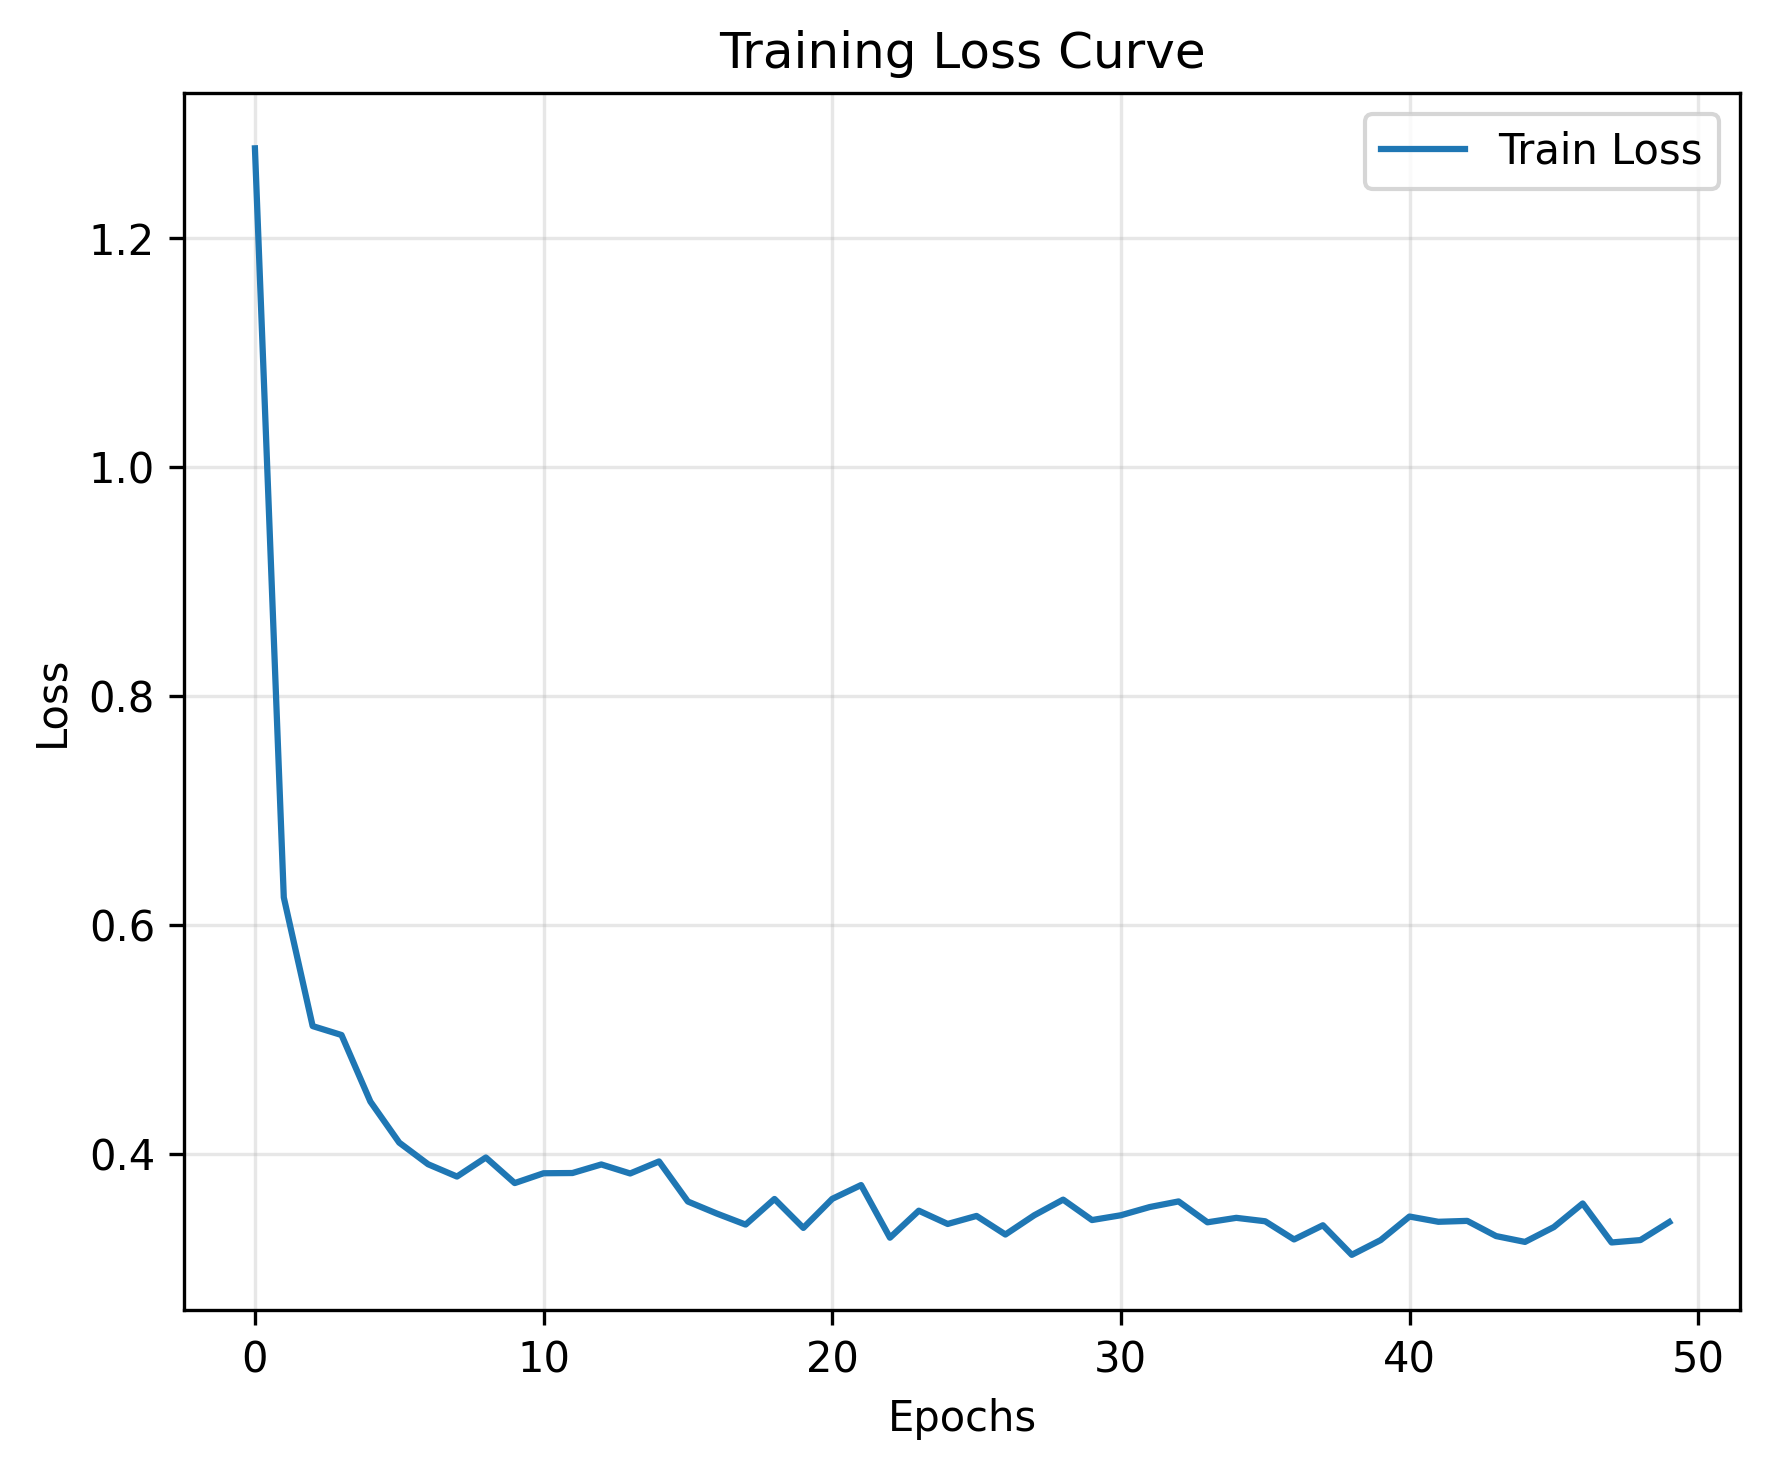

In [18]:
plt.figure(figsize=(6,5), dpi=300)

plt.plot(train_loss_list, label="Train Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Curve")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("loss_curve.pdf")

plt.show()

In [19]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, predicted, average=None)
recall = recall_score(y_test, predicted, average=None)
f1 = f1_score(y_test, predicted, average=None)

labels = ["Normal", "Soap", "Mud", "Blockage"]

for i in range(4):
    print(labels[i])
    print("Precision:", precision[i])
    print("Recall:", recall[i])
    print("F1:", f1[i])
    print()

Normal
Precision: 0.8571428571428571
Recall: 0.9574468085106383
F1: 0.9045226130653267

Soap
Precision: 0.8878504672897196
Recall: 0.8597285067873304
F1: 0.8735632183908046

Mud
Precision: 0.8376623376623377
Recall: 0.7371428571428571
F1: 0.78419452887538

Blockage
Precision: 0.7709923664122137
Recall: 0.808
F1: 0.7890625



### Export Weights From our Trained Model

In [20]:
import numpy as np

w1 = model.fc1.weight.detach().cpu().numpy()
b1 = model.fc1.bias.detach().cpu().numpy()

w2 = model.fc2.weight.detach().cpu().numpy()
b2 = model.fc2.bias.detach().cpu().numpy()

np.save("fc1_w.npy", w1)
np.save("fc1_b.npy", b1)
np.save("fc2_w.npy", w2)
np.save("fc2_b.npy", b2)

print("Weights exported")

Weights exported


### Convert Weights → Arduino Arrays

In [21]:
import numpy as np

def to_c_array(name, arr):
    flat = arr.flatten()
    s = f"float {name}[] = {{"
    s += ",".join([str(float(x)) for x in flat])
    s += "};"
    return s

w1 = np.load("fc1_w.npy")
b1 = np.load("fc1_b.npy")
w2 = np.load("fc2_w.npy")
b2 = np.load("fc2_b.npy")

print(to_c_array("W1", w1))
print(to_c_array("B1", b1))
print(to_c_array("W2", w2))
print(to_c_array("B2", b2))

float W1[] = {0.20614266395568848,0.7459182143211365,-0.054819606244564056,0.05580441653728485,-0.8299058079719543,-0.8107659220695496,-0.2831898331642151,-0.2469106912612915,-2.521542549133301,-0.1548531949520111,0.40458038449287415,-2.320427417755127,0.0930580198764801,-0.20136499404907227,0.016420476138591766,0.20293331146240234,0.28077536821365356,-0.05289195105433464,-0.34866631031036377,-0.09136319905519485,-0.3493088483810425,-0.5051845908164978,-0.7560728192329407,-0.6189167499542236,-1.5792663097381592,0.1879483163356781,1.0578705072402954,0.2553529441356659,-0.7954205870628357,0.8906930088996887,0.12898491322994232,-2.2435286045074463,0.5619052648544312,0.016199393197894096,-0.7144911885261536,1.0643352270126343,0.042775288224220276,0.019884193316102028,-0.20474818348884583,-0.28757432103157043,-0.12067444622516632,0.16129711270332336,-0.2778592109680176,-0.15267060697078705,-0.9725777506828308,-0.22900210320949554,-0.5853078365325928,-0.8021100759506226,-0.8027510643005371,0